# Model Setup

In [1]:
%load_ext autoreload
%autoreload 2

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import json
import sys
import time

TIMESFM_root = "*/Models/timesfm/src"

os.chdir(TIMESFM_root); sys.path.insert(0, TIMESFM_root)

import torch
import timesfm

os.chdir("*/1. Environment/")

from data_generator import make_walk
from dataset import build_dataset, load_overview, load_window
from metrics import conditional_mean_forecaster, naive_forecaster, squared_error, ratio_rmse_floor, skill_vs_naive, skill_vs_conditional, drift_mle, plugin_forecaster


/Users/tiesdilling/miniconda3/envs/ties_timesfm/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
torch.set_float32_matmul_precision("high")

model = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch")


In [3]:
model.compile(
    timesfm.ForecastConfig(
        max_context=1024,                 # >= CONTEXT_LEN
        max_horizon=512,                  # >= MAX_HORIZON
        normalize_inputs=True,            # z-scores the context; why sigma is a nuisance
        use_continuous_quantile_head=True, # gives q10..q90 alongside the point forecast
        force_flip_invariance=False,      # your walks are all mu > 0; keep asymmetry visible
        infer_is_positive=False,          # levels can go negative after centring
        fix_quantile_crossing=True,       # keeps q10 <= q90
    )
)

In [4]:
def forecast_timesfm(context, horizon):
    point_forecast, quantile_forecast = model.forecast(
        horizon=horizon,
        inputs=[context],
    )
    
    prediction = point_forecast[0]

    return prediction

In [5]:
data_path = "*/"

In [6]:

overview_data = load_overview(data_path)

ORIGIN      = int(overview_data["origin"].iloc[0])
MAX_HORIZON = int(overview_data["max_horizon"].iloc[0])
HORIZONS    = range(1, MAX_HORIZON + 1)
SIGMA = float(overview_data["sigma"].iloc[0])
print(ORIGIN, MAX_HORIZON, SIGMA, len(overview_data))

512 256 1.0 12500


In [7]:
overview_data

,walk_id,snr,seed,sigma,mu,origin,max_horizon
0,snr0.01_seed0,0.01,0,1.0,0.01,512,256
1,snr0.01_seed1,0.01,1,1.0,0.01,512,256
2,snr0.01_seed2,0.01,2,1.0,0.01,512,256
3,snr0.01_seed3,0.01,3,1.0,0.01,512,256
4,snr0.01_seed4,0.01,4,1.0,0.01,512,256
...,...,...,...,...,...,...,...
12495,snr5_seed95,5.00,95,1.0,5.00,512,256
12496,snr5_seed96,5.00,96,1.0,5.00,512,256
12497,snr5_seed97,5.00,97,1.0,5.00,512,256
12498,snr5_seed98,5.00,98,1.0,5.00,512,256


# Implementation

## L = 512

In [8]:
CONTEXT_LEN = 512

In [9]:
rows_context_512 = []

for i in range(len(overview_data)):
    walk = overview_data.iloc[i]

    context, future = load_window(
        walk["walk_id"], CONTEXT_LEN, ORIGIN, MAX_HORIZON, data_path
    )

    if i % 500 == 0:
        print(f"\r{i}/{len(overview_data)}", end="", flush=True)
    prediction  = forecast_timesfm(context, MAX_HORIZON)
    plugin      = plugin_forecaster(context, MAX_HORIZON)
    conditional = conditional_mean_forecaster(context, MAX_HORIZON, walk["mu"])
    naive       = naive_forecaster(context, MAX_HORIZON)

    for h in HORIZONS:
        rows_context_512.append({
            "walk_id":     walk["walk_id"],
            "snr":         walk["snr"],
            "seed":        walk["seed"],
            "sigma":       walk["sigma"],
            "mu":          walk["mu"],
            "context_len": CONTEXT_LEN,
            "horizon":     h,
            "model":       "timesfm",
            "actual":      future[h - 1],
            "forecast":    prediction[h - 1],
            "naive":       naive[h - 1],
            "plugin":      plugin[h - 1],
            "conditional": conditional[h - 1],
            "se_model":       squared_error(prediction,  future, h),
            "se_naive":       squared_error(naive,       future, h),
            "se_plugin":      squared_error(plugin,      future, h),
            "se_conditional": squared_error(conditional, future, h),
        })

predictions_context_512 = pd.DataFrame(rows_context_512)

0/12500

12000/12500

In [10]:
predictions_context_512

,walk_id,snr,seed,sigma,mu,context_len,horizon,model,actual,forecast,naive,plugin,conditional,se_model,se_naive,se_plugin,se_conditional
0,snr0.01_seed0,0.01,0,1.0,0.01,512,1,timesfm,0.152914,0.278999,0.0,-0.014330,0.01,0.015897,2.338258e-02,0.027970,0.020424
1,snr0.01_seed0,0.01,0,1.0,0.01,512,2,timesfm,-0.381044,0.272356,0.0,-0.028660,0.02,0.426932,1.451946e-01,0.124175,0.160836
2,snr0.01_seed0,0.01,0,1.0,0.01,512,3,timesfm,-0.504496,0.311516,0.0,-0.042990,0.03,0.665875,2.545158e-01,0.212988,0.285686
3,snr0.01_seed0,0.01,0,1.0,0.01,512,4,timesfm,0.803376,0.390473,0.0,-0.057320,0.04,0.170489,6.454132e-01,0.740797,0.582743
4,snr0.01_seed0,0.01,0,1.0,0.01,512,5,timesfm,-0.154444,0.402921,0.0,-0.071649,0.05,0.310656,2.385287e-02,0.006855,0.041797
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3199995,snr5_seed99,5.00,99,1.0,5.00,512,252,timesfm,1260.902970,1359.233521,0.0,1265.948489,1260.00,9668.897261,1.589876e+06,25.457272,0.815354
3199996,snr5_seed99,5.00,99,1.0,5.00,512,253,timesfm,1263.939192,1364.207153,0.0,1270.972095,1265.00,10053.664050,1.597542e+06,49.461718,1.125313
3199997,snr5_seed99,5.00,99,1.0,5.00,512,254,timesfm,1268.951206,1368.309692,0.0,1275.995700,1270.00,9872.108809,1.610237e+06,49.624891,1.099969
3199998,snr5_seed99,5.00,99,1.0,5.00,512,255,timesfm,1273.053372,1371.771606,0.0,1281.019305,1275.00,9745.289742,1.620665e+06,63.456080,3.789359


In [11]:

predictions_context_512.to_csv("*/predicitons_512_times_fm.csv")


## L = 256

In [8]:
CONTEXT_LEN = 256

In [9]:
rows_context_256 = []

for i in range(len(overview_data)):
    walk = overview_data.iloc[i]

    context, future = load_window(
        walk["walk_id"], CONTEXT_LEN, ORIGIN, MAX_HORIZON, data_path
    )

    if i % 500 == 0:
        print(f"\r{i}/{len(overview_data)}", end="", flush=True)
    prediction  = forecast_timesfm(context, MAX_HORIZON)
    plugin      = plugin_forecaster(context, MAX_HORIZON)
    conditional = conditional_mean_forecaster(context, MAX_HORIZON, walk["mu"])
    naive       = naive_forecaster(context, MAX_HORIZON)

    for h in HORIZONS:
        rows_context_256.append({
            "walk_id":     walk["walk_id"],
            "snr":         walk["snr"],
            "seed":        walk["seed"],
            "sigma":       walk["sigma"],
            "mu":          walk["mu"],
            "context_len": CONTEXT_LEN,
            "horizon":     h,
            "model":       "timesfm",
            "actual":      future[h - 1],
            "forecast":    prediction[h - 1],
            "naive":       naive[h - 1],
            "plugin":      plugin[h - 1],
            "conditional": conditional[h - 1],
            "se_model":       squared_error(prediction,  future, h),
            "se_naive":       squared_error(naive,       future, h),
            "se_plugin":      squared_error(plugin,      future, h),
            "se_conditional": squared_error(conditional, future, h),
        })

predictions_context_256 = pd.DataFrame(rows_context_256)

12000/12500

In [10]:
predictions_context_256

,walk_id,snr,seed,sigma,mu,context_len,horizon,model,actual,forecast,naive,plugin,conditional,se_model,se_naive,se_plugin,se_conditional
0,snr0.01_seed0,0.01,0,1.0,0.01,256,1,timesfm,0.152914,0.161035,0.0,-0.040656,0.01,0.000066,2.338258e-02,0.037469,0.020424
1,snr0.01_seed0,0.01,0,1.0,0.01,256,2,timesfm,-0.381044,0.131985,0.0,-0.081313,0.02,0.263199,1.451946e-01,0.089839,0.160836
2,snr0.01_seed0,0.01,0,1.0,0.01,256,3,timesfm,-0.504496,0.120644,0.0,-0.121969,0.03,0.390799,2.545158e-01,0.146327,0.285686
3,snr0.01_seed0,0.01,0,1.0,0.01,256,4,timesfm,0.803376,0.180458,0.0,-0.162625,0.04,0.388027,6.454132e-01,0.933158,0.582743
4,snr0.01_seed0,0.01,0,1.0,0.01,256,5,timesfm,-0.154444,0.156177,0.0,-0.203281,0.05,0.096485,2.385287e-02,0.002385,0.041797
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3199995,snr5_seed99,5.00,99,1.0,5.00,256,252,timesfm,1260.902970,1367.226318,0.0,1265.174318,1260.00,11304.654512,1.589876e+06,18.244415,0.815354
3199996,snr5_seed99,5.00,99,1.0,5.00,256,253,timesfm,1263.939192,1372.842529,0.0,1270.194851,1265.00,11859.936855,1.597542e+06,39.133264,1.125313
3199997,snr5_seed99,5.00,99,1.0,5.00,256,254,timesfm,1268.951206,1375.817017,0.0,1275.215384,1270.00,11420.301467,1.610237e+06,39.239921,1.099969
3199998,snr5_seed99,5.00,99,1.0,5.00,256,255,timesfm,1273.053372,1378.399658,0.0,1280.235917,1275.00,11097.839942,1.620665e+06,51.588943,3.789359


In [11]:

predictions_context_256.to_csv("*/predicitons_256_times_fm.csv")


## L = 128

In [12]:
CONTEXT_LEN = 128

In [13]:
rows_context_128 = []

for i in range(len(overview_data)):
    walk = overview_data.iloc[i]

    context, future = load_window(
        walk["walk_id"], CONTEXT_LEN, ORIGIN, MAX_HORIZON, data_path
    )

    if i % 500 == 0:
        print(f"\r{i}/{len(overview_data)}", end="", flush=True)
    prediction  = forecast_timesfm(context, MAX_HORIZON)
    plugin      = plugin_forecaster(context, MAX_HORIZON)
    conditional = conditional_mean_forecaster(context, MAX_HORIZON, walk["mu"])
    naive       = naive_forecaster(context, MAX_HORIZON)

    for h in HORIZONS:
        rows_context_128.append({
            "walk_id":     walk["walk_id"],
            "snr":         walk["snr"],
            "seed":        walk["seed"],
            "sigma":       walk["sigma"],
            "mu":          walk["mu"],
            "context_len": CONTEXT_LEN,
            "horizon":     h,
            "model":       "timesfm",
            "actual":      future[h - 1],
            "forecast":    prediction[h - 1],
            "naive":       naive[h - 1],
            "plugin":      plugin[h - 1],
            "conditional": conditional[h - 1],
            "se_model":       squared_error(prediction,  future, h),
            "se_naive":       squared_error(naive,       future, h),
            "se_plugin":      squared_error(plugin,      future, h),
            "se_conditional": squared_error(conditional, future, h),
        })

predictions_context_128 = pd.DataFrame(rows_context_128)

12000/12500

In [14]:
predictions_context_128

,walk_id,snr,seed,sigma,mu,context_len,horizon,model,actual,forecast,naive,plugin,conditional,se_model,se_naive,se_plugin,se_conditional
0,snr0.01_seed0,0.01,0,1.0,0.01,128,1,timesfm,0.152914,-0.058804,0.0,0.011189,0.01,0.044824,2.338258e-02,0.020086,0.020424
1,snr0.01_seed0,0.01,0,1.0,0.01,128,2,timesfm,-0.381044,-0.002357,0.0,0.022378,0.02,0.143404,1.451946e-01,0.162749,0.160836
2,snr0.01_seed0,0.01,0,1.0,0.01,128,3,timesfm,-0.504496,-0.125771,0.0,0.033567,0.03,0.143432,2.545158e-01,0.289511,0.285686
3,snr0.01_seed0,0.01,0,1.0,0.01,128,4,timesfm,0.803376,-0.106662,0.0,0.044756,0.04,0.828170,6.454132e-01,0.575505,0.582743
4,snr0.01_seed0,0.01,0,1.0,0.01,128,5,timesfm,-0.154444,-0.232585,0.0,0.055945,0.05,0.006106,2.385287e-02,0.044263,0.041797
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3199995,snr5_seed99,5.00,99,1.0,5.00,128,252,timesfm,1260.902970,1380.365356,0.0,1291.282869,1260.00,14271.261894,1.589876e+06,922.938322,0.815354
3199996,snr5_seed99,5.00,99,1.0,5.00,128,253,timesfm,1263.939192,1388.644287,0.0,1296.407008,1265.00,15551.360724,1.597542e+06,1054.159060,1.125313
3199997,snr5_seed99,5.00,99,1.0,5.00,128,254,timesfm,1268.951206,1390.744629,0.0,1301.531146,1270.00,14833.637854,1.610237e+06,1061.452502,1.099969
3199998,snr5_seed99,5.00,99,1.0,5.00,128,255,timesfm,1273.053372,1396.088745,0.0,1306.655285,1275.00,15137.702950,1.620665e+06,1129.088505,3.789359


In [15]:

predictions_context_128.to_csv("*/predicitons_128_times_fm.csv")


## L = 64

In [16]:
CONTEXT_LEN = 64

In [17]:
rows_context_64 = []

for i in range(len(overview_data)):
    walk = overview_data.iloc[i]

    context, future = load_window(
        walk["walk_id"], CONTEXT_LEN, ORIGIN, MAX_HORIZON, data_path
    )

    if i % 500 == 0:
        print(f"\r{i}/{len(overview_data)}", end="", flush=True)
    prediction  = forecast_timesfm(context, MAX_HORIZON)
    plugin      = plugin_forecaster(context, MAX_HORIZON)
    conditional = conditional_mean_forecaster(context, MAX_HORIZON, walk["mu"])
    naive       = naive_forecaster(context, MAX_HORIZON)

    for h in HORIZONS:
        rows_context_64.append({
            "walk_id":     walk["walk_id"],
            "snr":         walk["snr"],
            "seed":        walk["seed"],
            "sigma":       walk["sigma"],
            "mu":          walk["mu"],
            "context_len": CONTEXT_LEN,
            "horizon":     h,
            "model":       "timesfm",
            "actual":      future[h - 1],
            "forecast":    prediction[h - 1],
            "naive":       naive[h - 1],
            "plugin":      plugin[h - 1],
            "conditional": conditional[h - 1],
            "se_model":       squared_error(prediction,  future, h),
            "se_naive":       squared_error(naive,       future, h),
            "se_plugin":      squared_error(plugin,      future, h),
            "se_conditional": squared_error(conditional, future, h),
        })

predictions_context_64 = pd.DataFrame(rows_context_64)

12000/12500

In [18]:
predictions_context_64

,walk_id,snr,seed,sigma,mu,context_len,horizon,model,actual,forecast,naive,plugin,conditional,se_model,se_naive,se_plugin,se_conditional
0,snr0.01_seed0,0.01,0,1.0,0.01,64,1,timesfm,0.152914,0.331032,0.0,-0.102400,0.01,0.031726,2.338258e-02,0.065185,0.020424
1,snr0.01_seed0,0.01,0,1.0,0.01,64,2,timesfm,-0.381044,0.471304,0.0,-0.204800,0.02,0.726496,1.451946e-01,0.031062,0.160836
2,snr0.01_seed0,0.01,0,1.0,0.01,64,3,timesfm,-0.504496,0.699252,0.0,-0.307200,0.03,1.449008,2.545158e-01,0.038926,0.285686
3,snr0.01_seed0,0.01,0,1.0,0.01,64,4,timesfm,0.803376,0.289554,0.0,-0.409600,0.04,0.264013,6.454132e-01,1.471311,0.582743
4,snr0.01_seed0,0.01,0,1.0,0.01,64,5,timesfm,-0.154444,0.227762,0.0,-0.512000,0.05,0.146081,2.385287e-02,0.127846,0.041797
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3199995,snr5_seed99,5.00,99,1.0,5.00,64,252,timesfm,1260.902970,1311.773682,0.0,1310.411462,1260.00,2587.829353,1.589876e+06,2451.090874,0.815354
3199996,snr5_seed99,5.00,99,1.0,5.00,64,253,timesfm,1263.939192,1322.460693,0.0,1315.611508,1265.00,3424.766111,1.597542e+06,2670.028225,1.125313
3199997,snr5_seed99,5.00,99,1.0,5.00,64,254,timesfm,1268.951206,1323.446655,0.0,1320.811553,1270.00,2969.753987,1.610237e+06,2689.495630,1.099969
3199998,snr5_seed99,5.00,99,1.0,5.00,64,255,timesfm,1273.053372,1327.079956,0.0,1326.011599,1275.00,2918.871746,1.620665e+06,2804.573759,3.789359


In [19]:

predictions_context_64.to_csv("*/predicitons_64_times_fm.csv")


## L = 32

In [20]:
CONTEXT_LEN = 32

In [21]:
rows_context_32 = []

for i in range(len(overview_data)):
    walk = overview_data.iloc[i]

    context, future = load_window(
        walk["walk_id"], CONTEXT_LEN, ORIGIN, MAX_HORIZON, data_path
    )

    if i % 500 == 0:
        print(f"\r{i}/{len(overview_data)}", end="", flush=True)
    prediction  = forecast_timesfm(context, MAX_HORIZON)
    plugin      = plugin_forecaster(context, MAX_HORIZON)
    conditional = conditional_mean_forecaster(context, MAX_HORIZON, walk["mu"])
    naive       = naive_forecaster(context, MAX_HORIZON)

    for h in HORIZONS:
        rows_context_32.append({
            "walk_id":     walk["walk_id"],
            "snr":         walk["snr"],
            "seed":        walk["seed"],
            "sigma":       walk["sigma"],
            "mu":          walk["mu"],
            "context_len": CONTEXT_LEN,
            "horizon":     h,
            "model":       "timesfm",
            "actual":      future[h - 1],
            "forecast":    prediction[h - 1],
            "naive":       naive[h - 1],
            "plugin":      plugin[h - 1],
            "conditional": conditional[h - 1],
            "se_model":       squared_error(prediction,  future, h),
            "se_naive":       squared_error(naive,       future, h),
            "se_plugin":      squared_error(plugin,      future, h),
            "se_conditional": squared_error(conditional, future, h),
        })

predictions_context_32 = pd.DataFrame(rows_context_32)

12000/12500

In [22]:
predictions_context_32

,walk_id,snr,seed,sigma,mu,context_len,horizon,model,actual,forecast,naive,plugin,conditional,se_model,se_naive,se_plugin,se_conditional
0,snr0.01_seed0,0.01,0,1.0,0.01,32,1,timesfm,0.152914,0.004841,0.0,-0.023217,0.01,0.021926,2.338258e-02,0.031022,0.020424
1,snr0.01_seed0,0.01,0,1.0,0.01,32,2,timesfm,-0.381044,0.228769,0.0,-0.046434,0.02,0.371872,1.451946e-01,0.111964,0.160836
2,snr0.01_seed0,0.01,0,1.0,0.01,32,3,timesfm,-0.504496,0.226786,0.0,-0.069650,0.03,0.534773,2.545158e-01,0.189090,0.285686
3,snr0.01_seed0,0.01,0,1.0,0.01,32,4,timesfm,0.803376,0.051169,0.0,-0.092867,0.04,0.565815,6.454132e-01,0.803252,0.582743
4,snr0.01_seed0,0.01,0,1.0,0.01,32,5,timesfm,-0.154444,-0.040084,0.0,-0.116084,0.05,0.013078,2.385287e-02,0.001471,0.041797
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3199995,snr5_seed99,5.00,99,1.0,5.00,32,252,timesfm,1260.902970,1295.744995,0.0,1309.016155,1260.00,1213.966749,1.589876e+06,2314.878649,0.815354
3199996,snr5_seed99,5.00,99,1.0,5.00,32,253,timesfm,1263.939192,1292.237915,0.0,1314.210664,1265.00,800.817721,1.597542e+06,2527.220875,1.125313
3199997,snr5_seed99,5.00,99,1.0,5.00,32,254,timesfm,1268.951206,1303.266846,0.0,1319.405172,1270.00,1177.563126,1.610237e+06,2545.602723,1.099969
3199998,snr5_seed99,5.00,99,1.0,5.00,32,255,timesfm,1273.053372,1310.925171,0.0,1324.599681,1275.00,1434.273125,1.620665e+06,2657.021932,3.789359


In [23]:

predictions_context_32.to_csv("*/predicitons_32_times_fm.csv")


In [24]:
frames = [predictions_context_32, predictions_context_64,
          predictions_context_128, predictions_context_256]

wide = pd.concat(frames, ignore_index=True).pivot_table(
    index=["walk_id", "horizon"], columns="context_len", values="actual"
)
print(wide.nunique(axis=1).max())   # expect exactly 1

1


actual    distinct values per row (want 1): 1
se_naive  distinct values per row (want 1): 1
se_plugin distinct values per row (want 4): 4
rows per context_len: {32: 3200000, 64: 3200000, 128: 3200000, 256: 3200000}
naive column all zero: True


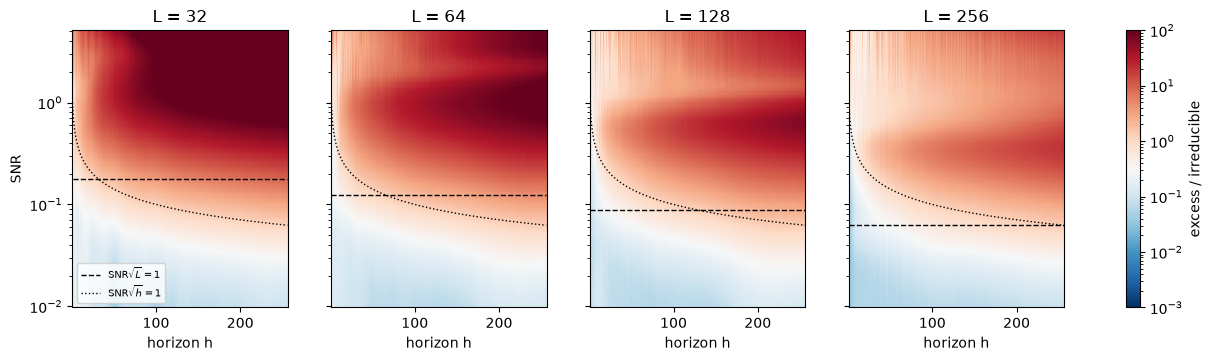

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.concat(
    [predictions_context_32, predictions_context_64,
     predictions_context_128, predictions_context_256],
    ignore_index=True,
)

# ---- integrity checks -------------------------------------------------
def n_distinct(values):
    return values.pivot_table(
        index=["walk_id", "horizon"], columns="context_len", values=values.name
    ).nunique(axis=1).max()

checks = {
    "actual identical across L (want 1)":    n_distinct(df.set_index(df.index)["actual"].rename("actual")) if False else None
}

wide_actual = df.pivot_table(index=["walk_id", "horizon"], columns="context_len", values="actual")
wide_naive  = df.pivot_table(index=["walk_id", "horizon"], columns="context_len", values="se_naive")
wide_plugin = df.pivot_table(index=["walk_id", "horizon"], columns="context_len", values="se_plugin")

print("actual    distinct values per row (want 1):", wide_actual.nunique(axis=1).max())
print("se_naive  distinct values per row (want 1):", wide_naive.nunique(axis=1).max())
print("se_plugin distinct values per row (want 4):", wide_plugin.nunique(axis=1).max())
print("rows per context_len:", df.groupby("context_len").size().to_dict())
print("naive column all zero:", np.allclose(df["naive"], 0.0))

# ---- phase diagram ---------------------------------------------------
df["excess"] = (df["forecast"] - df["conditional"]) ** 2
df["ratio"]  = df["excess"] / (df["horizon"] * df["sigma"] ** 2)

grid = (df.groupby(["context_len", "snr", "horizon"])["ratio"]
          .mean().reset_index())

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)

for ax, L in zip(axes, [32, 64, 128, 256]):
    sub = grid[grid["context_len"] == L].pivot(
        index="snr", columns="horizon", values="ratio"
    )
    im = ax.pcolormesh(
        sub.columns, sub.index, sub.values,
        norm=plt.matplotlib.colors.LogNorm(vmin=1e-3, vmax=1e2),
        cmap="RdBu_r", shading="nearest",
    )
    ax.set_yscale("log")
    ax.set_xlabel("horizon h")
    ax.set_title(f"L = {L}")

    # reference lines
    h = np.array(sorted(sub.columns))
    ax.plot(h, np.full_like(h, 1 / np.sqrt(L), dtype=float),
            "k--", lw=1, label=r"SNR$\sqrt{L}=1$")
    ax.plot(h, 1 / np.sqrt(h), "k:", lw=1, label=r"SNR$\sqrt{h}=1$")

axes[0].set_ylabel("SNR")
axes[0].legend(fontsize=7, loc="lower left")
fig.colorbar(im, ax=axes, label="excess / irreducible")
plt.show()

In [27]:
def implied_drift(g):
    return np.polyfit(g["horizon"].values, g["forecast"].values, 1)[0]

drift = (df.groupby(["context_len", "snr", "seed"])
           .apply(implied_drift).rename("mu_hat").reset_index())
drift = drift.merge(df[["snr", "mu"]].drop_duplicates(), on="snr")
drift["delta"] = drift["mu_hat"] - drift["mu"]

In [28]:
drift

,context_len,snr,seed,mu_hat,mu,delta
0,32,0.01,0,0.000120,0.01,-0.009880
1,32,0.01,1,0.000900,0.01,-0.009100
2,32,0.01,2,0.011365,0.01,0.001365
3,32,0.01,3,-0.014665,0.01,-0.024665
4,32,0.01,4,-0.000605,0.01,-0.010605
...,...,...,...,...,...,...
49995,256,5.00,95,5.213824,5.00,0.213824
49996,256,5.00,96,5.122944,5.00,0.122944
49997,256,5.00,97,5.188028,5.00,0.188028
49998,256,5.00,98,5.247692,5.00,0.247692


max ratio: 1322.607900959736
max vs_plugin: 1346.8652936971182


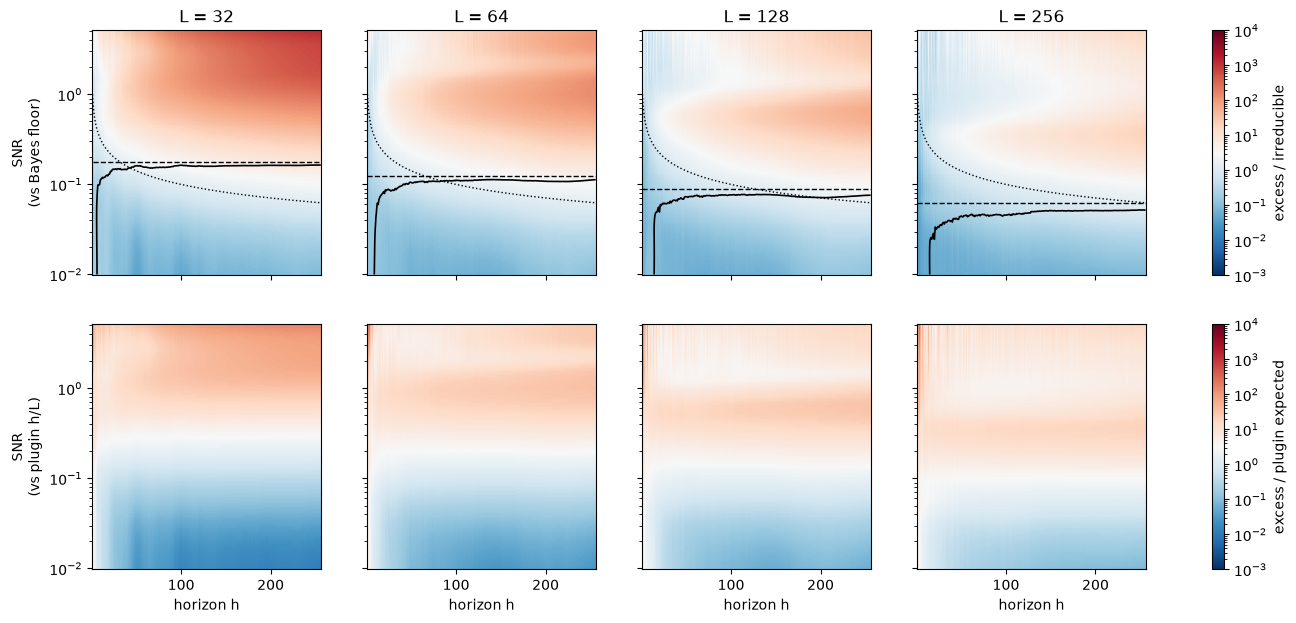

In [32]:
from matplotlib import colors

df["excess"] = (df["forecast"] - df["conditional"]) ** 2
df["ratio"]  = df["excess"] / (df["horizon"] * df["sigma"] ** 2)
df["vs_plugin"] = df["ratio"] * df["context_len"] / df["horizon"]

grid = (df.groupby(["context_len", "snr", "horizon"])[["ratio", "vs_plugin"]]
          .mean().reset_index())

print("max ratio:", grid["ratio"].max())
print("max vs_plugin:", grid["vs_plugin"].max())

context_lengths = [32, 64, 128, 256]
fig, axes = plt.subplots(2, 4, figsize=(17, 7), sharex=True, sharey=True)

for column, L in enumerate(context_lengths):
    sub = grid[grid["context_len"] == L]

    surface_ratio = sub.pivot(index="snr", columns="horizon", values="ratio")
    surface_vs    = sub.pivot(index="snr", columns="horizon", values="vs_plugin")

    horizons = np.array(sorted(surface_ratio.columns), dtype=float)
    snrs     = np.array(sorted(surface_ratio.index), dtype=float)
    plugin_line = horizons / L

    top = axes[0, column]
    image_top = top.pcolormesh(
        horizons, snrs, surface_ratio.values,
        norm=colors.LogNorm(vmin=1e-3, vmax=1e4),
        cmap="RdBu_r", shading="nearest",
    )
    contour_field = surface_ratio.values - plugin_line[None, :]
    top.contour(horizons, snrs, contour_field, levels=[0.0], colors="k", linewidths=1.2)
    top.plot(horizons, np.full_like(horizons, 1 / np.sqrt(L)), "k--", lw=1)
    top.plot(horizons, 1 / np.sqrt(horizons), "k:", lw=1)
    top.set_yscale("log")
    top.set_title(f"L = {L}")

    bottom = axes[1, column]
    image_bottom = bottom.pcolormesh(
        horizons, snrs, surface_vs.values,
        norm=colors.LogNorm(vmin=1e-3, vmax=1e4),
        cmap="RdBu_r", shading="nearest",
    )
    bottom.set_yscale("log")
    bottom.set_xlabel("horizon h")

axes[0, 0].set_ylabel("SNR\n(vs Bayes floor)")
axes[1, 0].set_ylabel("SNR\n(vs plugin h/L)")
fig.colorbar(image_top, ax=axes[0, :], label="excess / irreducible")
fig.colorbar(image_bottom, ax=axes[1, :], label="excess / plugin expected")
plt.show()

In [30]:
df["snr_bin"] = pd.cut(np.log10(df["snr"]), bins=12)
df["h_bin"]   = pd.cut(df["horizon"], bins=16)

coarse = (df.groupby(["context_len", "snr_bin", "h_bin"], observed=True)["ratio"]
            .mean().reset_index())
print(coarse[coarse["context_len"] == 128].pivot(
    index="snr_bin", columns="h_bin", values="ratio"
).round(2).to_string())

# --- patch-boundary check: jumps in the horizon profile ---
profile = (df[df["snr"].between(0.3, 2.0)]
             .groupby(["context_len", "horizon"])["ratio"].mean().reset_index())

for L in context_lengths:
    series = profile[profile["context_len"] == L].sort_values("horizon")
    values = series["ratio"].values
    jumps = np.abs(np.diff(values)) / np.abs(values[:-1])
    top_five = np.argsort(jumps)[-5:][::-1] + 2      # +2 -> horizon of the jump
    print(f"L={L}  largest relative jumps at h =", sorted(top_five.tolist()))

h_bin             (0.745, 16.938]  (16.938, 32.875]  (32.875, 48.812]  (48.812, 64.75]  (64.75, 80.688]  (80.688, 96.625]  (96.625, 112.562]  (112.562, 128.5]  (128.5, 144.438]  (144.438, 160.375]  (160.375, 176.312]  (176.312, 192.25]  (192.25, 208.188]  (208.188, 224.125]  (224.125, 240.062]  (240.062, 256.0]
snr_bin                                                                                                                                                                                                                                                                                                                 
(-2.003, -1.775]             0.10              0.08              0.07             0.07             0.07              0.07               0.07              0.08              0.08                0.09                0.11               0.14               0.17                0.18                0.17              0.16
(-1.775, -1.55]              0.10              0.08          

In [31]:
paths = df.pivot_table(
    index=["context_len", "snr", "seed"], columns="horizon", values="forecast"
)

horizons = np.array(paths.columns, dtype=float)
matrix   = paths.values

centred = horizons - horizons.mean()
slopes  = (matrix @ centred) / (centred ** 2).sum()
levels  = matrix.mean(axis=1) - slopes * horizons.mean()

fitted    = slopes[:, None] * horizons[None, :] + levels[:, None]
residuals = matrix - fitted

oscillation = paths.index.to_frame(index=False)
oscillation["slope"]        = slopes
oscillation["residual_sd"]  = residuals.std(axis=1)
oscillation["residual_max"] = np.abs(residuals).max(axis=1)

summary = (oscillation.groupby(["context_len", "snr"])["residual_sd"]
             .agg(["mean", "std", "min", "max"]))
print(summary.round(4).to_string())

                         mean      std     min      max
context_len snr                                        
32          0.010000   0.5043   0.3932  0.0656   2.2224
            0.010514   0.5048   0.3939  0.0648   2.2240
            0.011054   0.5053   0.3946  0.0639   2.2256
            0.011622   0.5058   0.3954  0.0629   2.2272
            0.012220   0.5063   0.3962  0.0619   2.2287
            0.012848   0.5069   0.3970  0.0609   2.2302
            0.013508   0.5074   0.3979  0.0599   2.2316
            0.014202   0.5079   0.3988  0.0587   2.2329
            0.014932   0.5085   0.3997  0.0576   2.2342
            0.015700   0.5091   0.4005  0.0564   2.2353
            0.016507   0.5096   0.4014  0.0552   2.2363
            0.017355   0.5102   0.4022  0.0539   2.2370
            0.018247   0.5107   0.4030  0.0527   2.2377
            0.019185   0.5112   0.4037  0.0513   2.2380
            0.020171   0.5118   0.4043  0.0500   2.2381
            0.021207   0.5123   0.4048  0.0487  

In [33]:
profile = (df[df["snr"].between(0.3, 2.0)]
             .groupby(["context_len", "horizon"])["ratio"].mean().reset_index())

for L in [32, 64, 128, 256]:
    series = profile[profile["context_len"] == L].sort_values("horizon")
    series = series[series["horizon"] >= 16]
    log_ratio = np.log(series["ratio"].values)
    curvature = np.abs(np.diff(log_ratio, n=2))
    horizons = series["horizon"].values[1:-1]
    worst = horizons[np.argsort(curvature)[-6:]]
    print(f"L={L}  sharpest curvature at h =", sorted(worst.tolist()))

L=32  sharpest curvature at h = [17, 20, 28, 31, 32, 42]
L=64  sharpest curvature at h = [17, 18, 19, 20, 26, 36]
L=128  sharpest curvature at h = [18, 19, 20, 23, 24, 30]
L=256  sharpest curvature at h = [18, 19, 21, 40, 42, 54]
